# Flood Mapping with Sentinel-1 Polarimetric SAR — 1. Change Detection

Step-by-step change detection for the paper:

> Isundwa et al., *Analytical Optimization of Polarimetric Change Detectors for
> Mapping Open and Grassland Flooding Using Sentinel-1. Case of Rupununi, Guyana.*
> IEEE JSTARS, 2026.

This notebook loads a pair of dual-pol SAR acquisitions (SNAP-exported ENVI
covariance elements), applies speckle filtering, and computes a bank of
polarimetric change detectors. The **accuracy assessment** lives in a separate
notebook (`02_accuracy_assessment.ipynb`).

**Note on the environment:** the per-pixel loop uses single-matrix LAPACK calls
(`np.linalg.eigh`, `scipy.linalg.eig`, `inv`). Batched `np.linalg` is avoided
because some local BLAS builds crash on stacked arrays.

## 1. Imports

In [13]:
import os
import json
import time
import numpy as np
from scipy import signal
import scipy.linalg as ln
import matplotlib.pyplot as plt

try:
    from tqdm import tqdm   # plain tqdm works in console and notebook
except ImportError:
    def tqdm(x, **k):
        return x

## 2. Reading the data (ENVI `.hdr` / `.img`)

A minimal ENVI reader — no `spectral` dependency. It parses the header for
`samples`, `lines`, `data type` and `byte order`, then loads the binary `.img`.
Each acquisition is stored as the covariance elements `C11`, `C22`, `C12`
(`C12` = `C12_real` + i·`C12_imag`).

In [2]:
# ENVI data type code -> numpy base dtype
_ENVI_DTYPE = {
    1: 'u1', 2: 'i2', 3: 'i4', 4: 'f4', 5: 'f8',
    6: 'c8', 9: 'c16', 12: 'u2', 13: 'u4', 14: 'i8', 15: 'u8',
}


def _parse_envi_header(hdr_path):
    """Parse the fields we need from an ENVI .hdr text file."""
    fields = {}
    with open(hdr_path, 'r') as f:
        for line in f:
            if '=' in line:
                k, v = line.split('=', 1)
                fields[k.strip().lower()] = v.strip()
    samples = int(fields['samples'])
    lines = int(fields['lines'])
    dcode = int(fields['data type'])
    border = int(fields.get('byte order', 0))
    base = _ENVI_DTYPE[dcode]
    dtype = np.dtype(('>' if border == 1 else '<') + base)   # 1 = big-endian
    return samples, lines, dtype


def Open_ENVI_Image(filename):
    """Open an ENVI binary image. `filename` is the path WITHOUT extension."""
    samples, lines, dtype = _parse_envi_header(filename + '.hdr')
    with open(filename + '.img', 'rb') as f:
        img = np.fromfile(f, dtype=dtype)
    # match the original pipeline: shape (samples, lines), Fortran order
    img = img.reshape((samples, lines), order='F').astype(dtype)
    return img


def Load_One_Date_Dual(path, date):
    """Load the covariance elements (C11, C22, C12 complex) for one date."""
    C11 = Open_ENVI_Image(path + 'C11_' + date)
    C22 = Open_ENVI_Image(path + 'C22_' + date)
    C12_real = Open_ENVI_Image(path + 'C12_real_' + date)
    C12_imag = Open_ENVI_Image(path + 'C12_imag_' + date)
    C12 = C12_real + 1j * C12_imag
    del C12_real, C12_imag
    return C11, C22, C12

## 3. Speckle filtering (boxcar multilook)

A simple boxcar average of the covariance elements reduces speckle before
change detection.

In [3]:
def Boxcar_Pol_filter_Dual(C11, C22, C12, win=(7, 7)):
    """Boxcar multilooking of the covariance elements."""
    w1, w2 = int(win[0]), int(win[1])
    kernel = np.ones((w1, w2), np.float32) / (w1 * w2)
    opt = dict(mode='same', boundary='fill', fillvalue=0)
    C11f = signal.convolve2d(C11, kernel, **opt)
    C22f = signal.convolve2d(C22, kernel, **opt)
    C12f = signal.convolve2d(C12, kernel, **opt)   # complex -> filtered complex
    return C11f, C22f, C12f

## 4. The detector bank

For every pixel we build the two 2×2 Hermitian covariance matrices
(`Ta` = C2 = during flood, `Tb` = C1 = reference) and compute:

| Detector | Meaning |
|---|---|
| `Dif1`, `Dif2` | OPDiff — max / min eigenvalue of `C2 − C1` |
| `Alpha1`, `Alpha2` | eigenvector angles of the difference |
| `Rat1`, `Rat2` | OPRatio — eigenvalues of `C1⁻¹ C2` |
| `RatDif` | Model 4 (mixed) — `Rat2² · Dif1` (headline detector) |
| `MonU1`, `MonU2` | Model 1 (monomial unitary) |
| `Lin1`, `Lin2` | Model 3 (linear) |
| `RatVV`, `RatVH` | simple backscatter ratios |
| `Wishart`, `Trace` | reference statistics |

Returns a **dictionary** of detector-name → 2-D array.

In [4]:
def compute_change_detectors(C11_a, C22_a, C12_a,
                             C11_b, C22_b, C12_b,
                             eps=1e-6, progress=True):
    """Compute all change detectors for one image pair, pixel by pixel.

    _a = image 2 (during flood / C2);  _b = image 1 (reference / C1).
    Returns dict of float32 (H, W) arrays, one per detector.
    """
    dima, dimr = C11_a.shape

    Dif1 = np.zeros((dima, dimr), np.float32)
    Dif2 = np.zeros((dima, dimr), np.float32)
    Alpha1 = np.zeros((dima, dimr), np.float32)
    Alpha2 = np.zeros((dima, dimr), np.float32)
    Rat1 = np.zeros((dima, dimr), np.float32)
    Rat2 = np.zeros((dima, dimr), np.float32)
    RatDif = np.zeros((dima, dimr), np.float32)
    MonU1 = np.zeros((dima, dimr), np.float32)
    MonU2 = np.zeros((dima, dimr), np.float32)
    Lin1 = np.zeros((dima, dimr), np.float32)
    Lin2 = np.zeros((dima, dimr), np.float32)
    Wishart = np.zeros((dima, dimr), np.float32)
    Trace = np.zeros((dima, dimr), np.float32)

    Ta = np.zeros((2, 2), dtype=np.complex128)
    Tb = np.zeros((2, 2), dtype=np.complex128)

    rows = tqdm(range(dima)) if progress else range(dima)
    for i in rows:
        for ii in range(dimr):
            # Build the two 2x2 Hermitian covariance matrices
            Ta[0, 0] = C11_a[i, ii] + eps
            Ta[1, 1] = C22_a[i, ii] + eps
            Ta[0, 1] = C12_a[i, ii]
            Ta[1, 0] = np.conj(Ta[0, 1])
            Tb[0, 0] = C11_b[i, ii] + eps
            Tb[1, 1] = C22_b[i, ii] + eps
            Tb[0, 1] = C12_b[i, ii]
            Tb[1, 0] = np.conj(Tb[0, 1])

            # ---- OPDiff : B = C2 - C1 (Hermitian) ----
            d2, v2 = np.linalg.eigh(Ta - Tb)        # ascending reals
            Dif1[i, ii] = d2[1]                     # max power difference
            Dif2[i, ii] = d2[0]                     # min power difference
            Alpha1[i, ii] = np.arccos(np.abs(v2[0, 1]))
            Alpha2[i, ii] = np.arccos(np.abs(v2[0, 0]))

            # ---- OPRatio : A = C1^{-1} C2 ----
            A = np.linalg.inv(Tb) @ Ta
            d1 = ln.eig(A)[0]
            d1a = np.abs(d1)
            Rat1[i, ii] = np.max(d1a)               # largest |eigenvalue|
            Rat2[i, ii] = 1.0 / np.min(d1a)         # reciprocal of smallest
            Trace[i, ii] = np.real(A[0, 0] + A[1, 1])

            # ---- Model 4 (mixed) : headline detector  Rat2^2 * Dif1 ----
            RatDif[i, ii] = Rat2[i, ii] ** 2 * Dif1[i, ii]

            # ---- Model 1 (monomial unitary) : whiten C1 with C2 ----
            wa, va = np.linalg.eigh(Ta)             # C2 Hermitian PD
            wa = np.clip(wa, 1e-10, None)
            Ta_is = (va * (1.0 / np.sqrt(wa))) @ va.conj().T   # C2^{-1/2}
            Tm_u = Ta_is @ Tb @ Ta_is
            lam_u = np.linalg.eigvalsh(Tm_u)
            m1 = lam_u * (lam_u - 1.0)
            MonU1[i, ii] = np.max(m1)
            MonU2[i, ii] = np.min(m1)

            # ---- Model 3 (linear) : faithful to original (ELEMENT-WISE sqrt) ----
            Ta_sqrt = np.sqrt(Ta)                   # element-wise, as original code
            Tm_l = Ta_sqrt @ Tb @ Ta_sqrt
            dl = ln.eig(Tm_l)[0]
            Lin1[i, ii] = np.real(dl[1])
            Lin2[i, ii] = np.real(dl[0])

            # ---- Wishart ----
            detA = Ta[0, 0] * Ta[1, 1] - Ta[0, 1] * Ta[1, 0]
            detB = Tb[0, 0] * Tb[1, 1] - Tb[0, 1] * Tb[1, 0]
            Tavg = (Ta + Tb) / 2.0
            detAvg = Tavg[0, 0] * Tavg[1, 1] - Tavg[0, 1] * Tavg[1, 0]
            Wishart[i, ii] = np.abs(detA) * np.abs(detB) / (np.abs(detAvg) ** 2 + eps)

    # ---- Simple backscatter ratios (vectorised, no LAPACK) ----
    RatVV = ((C11_a + eps) / (C11_b + eps)).astype(np.float32)
    RatVH = ((C22_a + eps) / (C22_b + eps)).astype(np.float32)

    return {
        'Dif1': Dif1, 'Dif2': Dif2,
        'Alpha1': Alpha1, 'Alpha2': Alpha2,
        'Rat1': Rat1, 'Rat2': Rat2,
        'RatDif': RatDif,
        'MonU1': MonU1, 'MonU2': MonU2,
        'Lin1': Lin1, 'Lin2': Lin2,
        'RatVV': RatVV, 'RatVH': RatVH,
        'Wishart': Wishart, 'Trace': Trace,
    }

## 5. Configuration

Point `DATA_ROOT` at the folder that holds one sub-folder per date. Set `CROP`
to a small integer for a quick test (centre window), or `None` to process the
full scene (the per-pixel loop on a full scene can take tens of minutes).

In [5]:
# --- Guyana workflow (uncomment and point at your drive) ---
DATA_ROOT = r'D:\FLOOD\Guyana\4_Stack_Sorted'
DATE_REF  = '20170329'
DATE_TEST = '20170715'

WIN  = (7, 7)    # boxcar window
CROP = None       # centre crop size in pixels; set to None for the full scene

## 6. Load and filter the image pair

In [6]:
ref_dir  = os.path.join(DATA_ROOT, DATE_REF) + os.sep
test_dir = os.path.join(DATA_ROOT, DATE_TEST) + os.sep

print(f'Loading reference {DATE_REF} ...')
C11b, C22b, C12b = Load_One_Date_Dual(ref_dir, DATE_REF)
print(f'Loading test      {DATE_TEST} ...')
C11a, C22a, C12a = Load_One_Date_Dual(test_dir, DATE_TEST)
print('Full scene size:', C11a.shape)

if CROP is not None:
    r0 = C11a.shape[0] // 2
    c0 = C11a.shape[1] // 2
    sl = (slice(r0, r0 + CROP), slice(c0, c0 + CROP))
    C11b, C22b, C12b = C11b[sl], C22b[sl], C12b[sl]
    C11a, C22a, C12a = C11a[sl], C22a[sl], C12a[sl]
    print('Cropped to:', C11a.shape)

print('Boxcar filtering ...')
C11b, C22b, C12b = Boxcar_Pol_filter_Dual(C11b, C22b, C12b, WIN)
C11a, C22a, C12a = Boxcar_Pol_filter_Dual(C11a, C22a, C12a, WIN)
print('Done.')


Loading reference 20170329 ...
Loading test      20170715 ...
Full scene size: (6704, 2734)
Boxcar filtering ...
Done.


## 7. Run the change detection

In [7]:
t0 = time.time()
det = compute_change_detectors(C11a, C22a, C12a, C11b, C22b, C12b)
print(f'Computed {len(det)} detectors in {time.time() - t0:.1f} s')

print('\n--- detector summary (min / max / mean) ---')
for k, v in det.items():
    print(f'  {k:8s} {np.nanmin(v): .4g}  ..  {np.nanmax(v): .4g}  (mean {np.nanmean(v): .4g})')

100%|██████████████████████████████████████████████████████████████████████████████| 6704/6704 [59:58<00:00,  1.86it/s]


Computed 15 detectors in 3598.7 s

--- detector summary (min / max / mean) ---
  Dif1     -0.1752  ..   11.29  (mean  0.03416)
  Dif2     -1.451  ..   0.2592  (mean -0.00631)
  Alpha1    1.829e-05  ..   1.571  (mean  0.6018)
  Alpha2    0  ..   1.571  (mean  0.969)
  Rat1      2.033e-05  ..   1.513e+05  (mean  13.87)
  Rat2      2.654e-05  ..   2.804e+05  (mean  5.499)
  RatDif   -3.869e+09  ..   10.49  (mean -3672)
  MonU1    -0.25  ..   7.865e+10  (mean  1.597e+05)
  MonU2    -0.25  ..   2.421e+09  (mean  9869)
  Lin1      5.213e-14  ..   0.2816  (mean  0.001009)
  Lin2      1.608e-13  ..   17.16  (mean  0.02671)
  RatVV     3.627e-06  ..   1.508e+05  (mean  13.12)
  RatVH     1.853e-05  ..   3.928e+04  (mean  4.747)
  Wishart   1e-18  ..   0.9999  (mean  0.6076)
  Trace     2.389e-05  ..   1.666e+05  (mean  18.07)


## 8. Plot the detector results (before thresholding)

The dictionary below controls **which detectors are plotted**. Comment out any
line (or set it to `None`) to skip that detector. Each entry is
`'Name': dict(cmap=..., sym=...)` where `sym=True` centres the colour scale on
zero (useful for difference-type detectors).

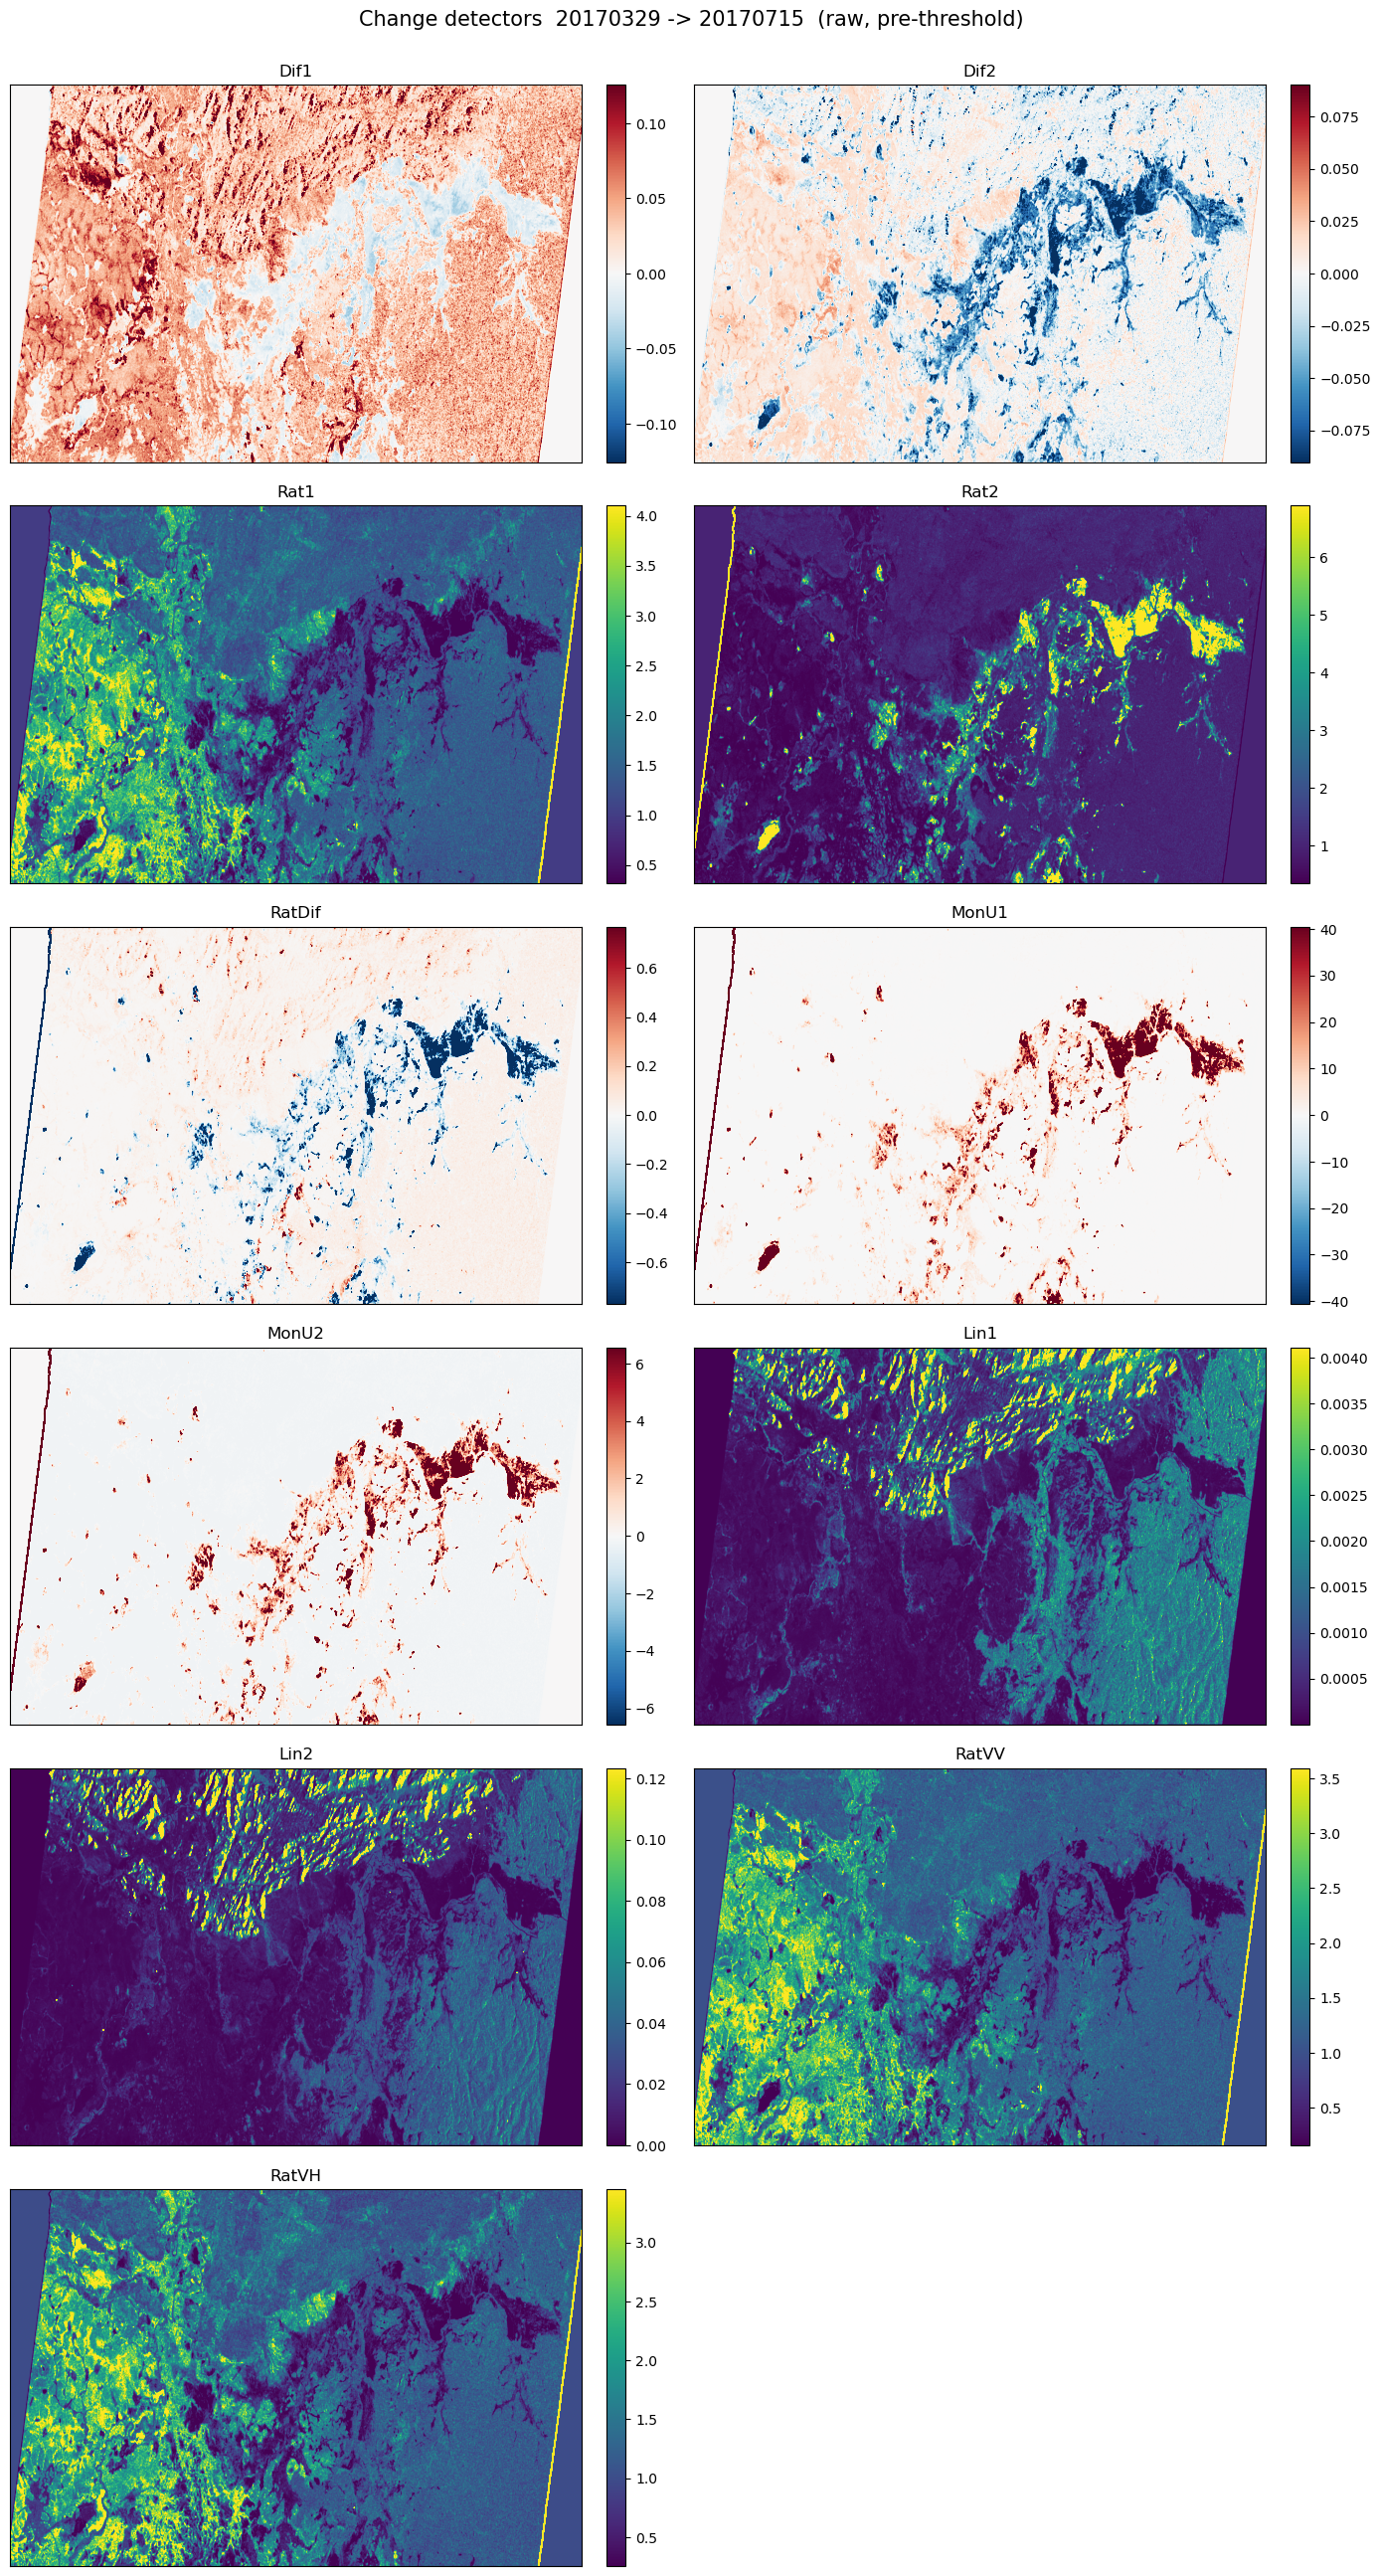

In [17]:
# Comment out any line to drop that detector from the figure.
PLOT_DETECTORS = {
    'Dif1':   dict(cmap='RdBu_r', sym=True),
    'Dif2':   dict(cmap='RdBu_r', sym=True),
    'Rat1':   dict(cmap='viridis', sym=False),
    'Rat2':   dict(cmap='viridis', sym=False),
    'RatDif': dict(cmap='RdBu_r', sym=True),
    'MonU1':  dict(cmap='RdBu_r', sym=True),
    'MonU2':  dict(cmap='RdBu_r', sym=True),
    'Lin1':   dict(cmap='viridis', sym=False),
    'Lin2':   dict(cmap='viridis', sym=False),
    'RatVV':  dict(cmap='viridis', sym=False),
    'RatVH':  dict(cmap='viridis', sym=False),
#     'Wishart':dict(cmap='viridis', sym=False),
#     'Trace':  dict(cmap='viridis', sym=False),
    # 'Alpha1': dict(cmap='twilight', sym=False),
    # 'Alpha2': dict(cmap='twilight', sym=False),
}


def plot_detectors(det, selection, ncols=2, pct=(2, 98)):
    """Show each selected detector as a map with a robust percentile stretch."""
    names = [n for n in selection if selection[n] is not None and n in det]
    n = len(names)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 4.3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, name in zip(axes, names):
        opt = selection[name]
        data = det[name].T   # (samples, lines) -> (rows, cols) for display
        vmin, vmax = np.nanpercentile(data, pct)
        if opt.get('sym'):
            m = max(abs(vmin), abs(vmax))
            vmin, vmax = -m, m
        im = ax.imshow(data, cmap=opt.get('cmap', 'viridis'),
                       vmin=vmin, vmax=vmax, aspect='auto')
        ax.set_title(name, fontsize=12)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for ax in axes[n:]:
        ax.axis('off')
    fig.suptitle(f'Change detectors  {DATE_REF} -> {DATE_TEST}  (raw, pre-threshold)',
                 fontsize=15, y=1.002)
    fig.tight_layout()
    return fig


fig = plot_detectors(det, PLOT_DETECTORS)
plt.show()

## 9. Saving detector outputs (before thresholding)

 (change detection -> results dir)

In [9]:
# =============================================================================
# Saving detector outputs  (change detection -> results dir)
# =============================================================================
def save_detectors(det, results_dir, date, transpose=False):
    """
    Save every detector array to `results_dir` as `<name>_<date>.npy`.

    The accuracy-assessment notebook reloads these with `load_detectors`.

    Parameters
    ----------
    det : dict[str, (H, W) array]   output of compute_change_detectors
    results_dir : str or Path       folder to write into (created if missing)
    date : str                      tag used in the file names, e.g. '20170715'
    transpose : bool                save each array transposed (.T) so it matches
                                    the orientation of your reference masks

    Returns
    -------
    results_dir (str)
    """
    results_dir = str(results_dir)
    os.makedirs(results_dir, exist_ok=True)
    for name, arr in det.items():
        a = np.asarray(arr)
        if transpose:
            a = a.T
        np.save(os.path.join(results_dir, f"{name}_{date}.npy"), a.astype(np.float32))
    # small manifest for sanity / reloading
    shape = list(np.asarray(next(iter(det.values()))).T.shape) if transpose \
        else list(np.asarray(next(iter(det.values()))).shape)
    manifest = {"date": date, "detectors": list(det.keys()),
                "shape": shape, "transpose": transpose}
    with open(os.path.join(results_dir, f"manifest_{date}.json"), "w") as f:
        json.dump(manifest, f, indent=2)
    print(f"Saved {len(det)} detectors for {date} -> {os.path.abspath(results_dir)}")
    return results_dir


In [ ]:
try:
    HERE = os.path.dirname(os.path.abspath(__file__))   # when run as a .py script
except NameError:
    HERE = os.getcwd()                                  # when run inside a notebook
RESULTS_DIR = os.path.join(HERE, 'results')   # <- change to taste

save_detectors(det, RESULTS_DIR, DATE_TEST, transpose=False)
print('Results dir (absolute):', os.path.abspath(RESULTS_DIR))